# Pérdida esperada de una cuenta: estructura de plazos, pérdida dado el incumplimiento, exposición y descuento

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** tema 01 (primeros pasos), cuadernos 01 y 02
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este cuaderno puedes:

- construir la supervivencia, la probabilidad marginal y la acumulada de incumplimiento a partir de un hazard, y volver desde cualquiera de las otras dos al mismo hazard;
- explicar por qué un préstamo que también puede prepagarse tiene una incidencia de incumplimiento menor que la que sugiere su hazard de incumplimiento, y por qué la PD de vida completa de Contraste igual trata el prepago como censura;
- escribir la pérdida crediticia esperada (PCE) de una cuenta como una suma de pérdidas marginales descontadas, y leer la PCE a 12 meses y la PCE de vida completa como la misma suma sobre dos horizontes;
- enunciar la convención de descuento (a mitad de período, a la tasa de interés efectiva original) y medir qué cambia;
- comparar un recálculo con el artefacto versionado, nombrando la versión del motor que lo calculó.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C06 (PD de vida completa tipo hipotecario, etapas y PCE de IFRS 9) tal como Contraste lo versiona, a la fecha de reporte 2008-12-31. Los préstamos son los préstamos 7(a) a pequeñas empresas de la Administración de Pequeños Negocios de EE. UU. (SBA), el gemelo público del caso hipotecario (Obras del Gobierno de EE. UU., clase de licencia `mirror-allowed`; no se usan los datos de Freddie Mac, falta la cuenta del propietario). El pipeline ajustó tres peldaños de PD de vida completa con los préstamos conocidos a la fecha de reporte, los proyectó bajo tres escenarios macroeconómicos y versionó el resultado.

- **Archivos que se leen:** `data/derived/C06/rd-2008-12.json` para los ajustes, los horizontes y las estructuras de plazos (`outputs.term_structures`), y `data/derived/C06/models-rd-2008-12.json` para la pérdida dado el incumplimiento de cada segmento (`fit.lgd.segments`).
- **Lo que los archivos no tienen:** el saldo y la tasa de interés de una cuenta. La exposición y la tasa que se usan abajo son por eso **insumos declarados de esta lección**, rotulados como tales; la curva de PD y la pérdida dado el incumplimiento son las versionadas.

La celda siguiente carga ambos archivos e imprime los ajustes, los horizontes y la versión del motor que los calculó junto a la versión instalada ahora.

In [2]:
# Cargar el artefacto de la fecha de reporte y el archivo de modelos del caso C06 (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
case = json.loads((ROOT / "data" / "derived" / "C06" / "rd-2008-12.json").read_text(encoding="utf-8"))
models = json.loads((ROOT / "data" / "derived" / "C06" / "models-rd-2008-12.json").read_text(encoding="utf-8"))
out = case["outputs"]

print("fecha de reporte:", out["reporting_date"], "|", out["currency"], "| período en meses:", out["period_months"])
print("horizontes:", out["horizon"])
print("convención de descuento:", out["settings"]["discount_convention"], "| base de la tasa:", out["settings"]["eir_basis"])
print("motor que calculó el artefacto:", case["provenance"]["riskvalidation_version"], "| motor instalado ahora:", md.version("riskvalidation"))
print("escenarios y ponderaciones:", [(s["id"], s["weight"]) for s in out["scenarios"]])
print("segmentos:", [s["id"] for s in models["fit"]["segments"]])

fecha de reporte: 2008-12-31 | USD | período en meses: 3
horizontes: {'stage1_months': 12, 'lifetime_cap_months': 120}
convención de descuento: mid-period | base de la tasa: original
motor que calculó el artefacto: 0.5.0 | motor instalado ahora: 0.8.1
escenarios y ponderaciones: [('baseline', 0.6), ('adverse', 0.3), ('severely-adverse', 0.1)]
segmentos: ['term-le-60', 'term-61-120', 'term-121-240', 'term-gt-240']


## Método

El motor de Contraste enuncia la estructura de plazos y la PCE con las identidades de IFRS 9 tal como las escribe la literatura de análisis de supervivencia (Botha y Verster, 2025, ecuaciones 6 a 10). Para los períodos $t = 1, \dots, T$ posteriores a la fecha de reporte, con $h(t)$ la probabilidad de incumplir en el período $t$ dado que se sobrevive hasta su inicio (el hazard discreto):

$$S(t) = \prod_{u=1}^{t}\bigl(1 - h(u)\bigr), \qquad q(t) = S(t-1)\,h(t), \qquad F(t) = \sum_{u=1}^{t} q(u) = 1 - S(t), \qquad h(t) = \frac{q(t)}{S(t-1)}$$

Aquí $S$ es la supervivencia, $q$ la probabilidad incondicional (marginal) de incumplimiento del período, $F$ la PD acumulada y $S(0) = 1$. La PCE de una cuenta en un escenario es la suma de las pérdidas marginales descontadas (GPPC 2016, sección 2.1.1.2; IFRS 9 B5.5.28 y B5.5.43 a B5.5.44):

$$\mathrm{PCE}(T) = \sum_{t=1}^{T} q(t)\; \mathrm{PDI}(t)\; \mathrm{EAD}(t)\; \mathrm{FD}(t), \qquad \mathrm{FD}(t) = (1 + r)^{-\delta(t)/12}$$

con $r$ la tasa de interés efectiva (TIE) original y $\delta(t)$ los meses desde la fecha de reporte hasta la fecha de pérdida supuesta del período $t$: el punto medio del período en la convención documentada de Contraste, el final del período en la alternativa. $T$ es 12 meses para la PCE a 12 meses (Etapa 1) y la vida esperada para la PCE de vida completa (Etapa 2). La norma fija el objetivo, no la fórmula, y la tasa de descuento es la TIE, nunca una tasa libre de riesgo (IFRS 9 B5.5.44).

Cada paso siguiente llama al motor (`riskvalidation.provisions`) y, donde la definición es lo bastante corta, la verifica con arreglos simples. La verificación es una lectura de la definición, no una segunda implementación.

### Paso 1: la estructura de plazos de un segmento

El artefacto guarda, para cada segmento y escenario, el hazard, la PD marginal y la PD acumulada por trimestre. Tomamos la curva ponderada por escenarios del segmento de préstamos con plazo de más de 20 años (`term-gt-240`), la curva que lleva un préstamo largo, y reconstruimos toda la estructura desde su hazard con `from_hazard`. La celda lee luego las tres identidades sobre los arreglos y compara la PD marginal y la acumulada del motor con las versionadas.

In [3]:
# Reconstruir la estructura de plazos desde el hazard versionado y leer las tres identidades sobre los arreglos
from riskvalidation.provisions import term_structure as tsm

SEGMENT = "term-gt-240"
rows = {(r["scenario_id"], r["segment_id"]): r for r in out["term_structures"]}
curve = rows[("weighted", SEGMENT)]
months = np.array(curve["months"])
hazard = np.array(curve["hazard"])

ts = tsm.from_hazard(hazard, months)
survival_before = np.concatenate([[1.0], ts.survival[:-1]])
print("períodos:", len(months), "| último mes:", int(months[-1]))
print("S(t) = prod(1 - h):", si_no(np.allclose(ts.survival, np.cumprod(1.0 - hazard))))
print("q(t) = S(t-1) h(t):", si_no(np.allclose(ts.marginal, survival_before * hazard)))
print("F(t) = sum q = 1 - S:", si_no(np.allclose(ts.cumulative, 1.0 - ts.survival)), si_no(np.allclose(ts.cumulative, np.cumsum(ts.marginal))))
print("PD marginal igual a la versionada con tolerancia 1e-9:", si_no(np.allclose(ts.marginal, np.array(curve["marginal_pd"]), atol=1e-9, rtol=0)))
print("PD acumulada igual a la versionada con tolerancia 1e-9:", si_no(np.allclose(ts.cumulative, np.array(curve["cumulative_pd"]), atol=1e-9, rtol=0)))
print("calculado por el motor", case["provenance"]["riskvalidation_version"], "| leído con el motor", md.version("riskvalidation"))
for k in (0, 3, 19, 39):
    print("mes", int(months[k]), "| h:", round(float(ts.hazard[k]), 6), "| q:", round(float(ts.marginal[k]), 6), "| F:", round(float(ts.cumulative[k]), 6), "| S:", round(float(ts.survival[k]), 6))

períodos: 40 | último mes: 120
S(t) = prod(1 - h): sí
q(t) = S(t-1) h(t): sí
F(t) = sum q = 1 - S: sí sí
PD marginal igual a la versionada con tolerancia 1e-9: sí
PD acumulada igual a la versionada con tolerancia 1e-9: sí
calculado por el motor 0.5.0 | leído con el motor 0.8.1
mes 3 | h: 0.001589 | q: 0.001589 | F: 0.001589 | S: 0.998411
mes 12 | h: 0.001548 | q: 0.001541 | F: 0.006188 | S: 0.993812
mes 60 | h: 0.001166 | q: 0.001134 | F: 0.028451 | S: 0.971549
mes 120 | h: 0.000698 | q: 0.000667 | F: 0.045763 | S: 0.954237


### Paso 2: tres entradas, un solo hazard

Un banco rara vez parte de un hazard. Una scorecard o una tabla de cosechas da la PD acumulada desde la fecha de reporte, una curva regulatoria da la PD marginal. `from_marginal` y `from_cumulative` toman esos datos y devuelven la misma `TermStructure`, con $h(t) = q(t)/S(t-1)$. La celda alimenta a cada una con la curva reconstruida en el paso 1 y verifica que el hazard vuelve. Las entradas deben ser válidas: la PD acumulada estrictamente creciente dentro de $(0, 1)$, las PD marginales con suma menor que 1.

In [4]:
# Recuperar el hazard desde la PD marginal y desde la acumulada, y mostrar qué rechaza el motor
from_marginal = tsm.from_marginal(ts.marginal, months)
from_cumulative = tsm.from_cumulative(ts.cumulative, months)
print("hazard recuperado desde la PD marginal:", si_no(np.allclose(from_marginal.hazard, hazard, atol=1e-12, rtol=0)))
print("hazard recuperado desde la PD acumulada:", si_no(np.allclose(from_cumulative.hazard, hazard, atol=1e-12, rtol=0)))

# Una PD acumulada que baja no es una PD acumulada: el motor la rechaza y dice por qué
bad = ts.cumulative.copy()
bad[5] = bad[4]
try:
    tsm.from_cumulative(bad, months)
except ValueError as error:
    print("rechazado:", type(error).__name__, "| el mensaje nombra la regla, en el idioma del motor:", si_no(len(str(error)) > 0))

hazard recuperado desde la PD marginal: sí
hazard recuperado desde la PD acumulada: sí
rechazado: ValueError | el mensaje nombra la regla, en el idioma del motor: sí


### Paso 3: la PD sobre una ventana

La PCE a 12 meses necesita la PD del primer año, y las etapas del cuaderno 02 necesitan la PD de la vida restante dado que se sobrevive al primer aniversario. `forward_pd` del motor devuelve la PD condicional sobre $(a, b]$ dado que se sobrevive hasta $a$:

$$\mathrm{PD}(a, b) = \frac{S(a) - S(b)}{S(a)}$$

La celda pide el primer año, los meses 12 a 120 y la vida completa, y verifica la última contra la PD acumulada.

In [5]:
# PD condicional sobre tres ventanas, y la verificación de la ventana de vida completa contra F(T)
first_year = float(tsm.forward_pd(ts, 0, 12))
remaining_life = float(tsm.forward_pd(ts, 12, 120))
whole_life = float(tsm.forward_pd(ts, 0, 120))
print("PD de los primeros 12 meses:", round(first_year, 6))
print("PD de los meses 12 a 120 dado que se sobrevive al mes 12:", round(remaining_life, 6))
print("PD de la vida completa:", round(whole_life, 6), "| F(T):", round(float(ts.cumulative[-1]), 6))
print("el primer año y el resto componen la vida completa:", si_no(np.isclose(1.0 - (1.0 - first_year) * (1.0 - remaining_life), whole_life)))

PD de los primeros 12 meses: 0.006188
PD de los meses 12 a 120 dado que se sobrevive al mes 12: 0.039822
PD de la vida completa: 0.045763 | F(T): 0.045763
el primer año y el resto componen la vida completa: sí


### Paso 4: el prepago como salida competitiva

Un préstamo sale del libro por incumplimiento o por pago. Si el pago es posible, el préstamo deja de estar expuesto en los períodos siguientes, así que la incidencia de incumplimiento es menor que la de un hazard de incumplimiento que lo ignora. Con hazards por causa $h^D$ y $h^P$, `competing_risks` del motor calcula $S^{\mathrm{all}}(t) = \prod_u (1 - h^D(u) - h^P(u))$ y la incidencia de incumplimiento $q^D(t) = S^{\mathrm{all}}(t-1)\,h^D(t)$ (Botha y Verster, 2025; IFRS 9 B5.5.51 pide el efecto de los prepagos esperados). Nota que $\sum q^D \ne 1 - S^{\mathrm{all}}$: esta última cuenta también los préstamos que se pagaron.

El C06 de Contraste no lleva un hazard de prepago: el hallazgo versionado `F-PREPAYMENT` trata el prepago como censura, así que su PD de vida completa es el hazard de incumplimiento por causa. Para mostrar el efecto, la celda suma al hazard de incumplimiento versionado un hazard de prepago **declarado e ilustrativo** de 1 % por trimestre. No es una estimación de Contraste.

In [6]:
# Sumar un hazard de prepago declarado y comparar la incidencia de incumplimiento con la curva de riesgo único
PREPAY_HAZARD = 0.01  # insumo ilustrativo de la lección, por trimestre
competing = tsm.competing_risks(hazard, np.full(hazard.shape, PREPAY_HAZARD), months)

print("incumplimiento acumulado, solo el hazard de incumplimiento:", round(float(ts.cumulative[-1]), 6))
print("incidencia acumulada de incumplimiento con prepago:", round(float(competing.cumulative_default[-1]), 6))
print("probabilidad de salir del libro por incumplimiento o prepago:", round(float(1.0 - competing.survival_all[-1]), 6))
print("la incidencia no es 1 - S_todo:", si_no(not np.isclose(competing.cumulative_default[-1], 1.0 - competing.survival_all[-1])))
print("PD a futuro, meses 12 a 120, con prepago:", round(float(tsm.forward_pd(competing, 12, 120)), 6))

incumplimiento acumulado, solo el hazard de incumplimiento: 0.045763
incidencia acumulada de incumplimiento con prepago: 0.039038
probabilidad de salir del libro por incumplimiento o prepago: 0.361945
la incidencia no es 1 - S_todo: sí
PD a futuro, meses 12 a 120, con prepago: 0.034509


### Paso 5: el factor de descuento

Cada pérdida se trae a la fecha de reporte a la TIE original. `discount_factors` devuelve $(1 + r)^{-\delta/12}$ para cada cuenta y período. Con la convención a mitad de período una pérdida del primer trimestre se descuenta 1,5 meses, no 3. La tasa es un **insumo declarado** (8 % anual, un insumo de la lección; el artefacto no guarda una tasa por cuenta). La celda imprime los primeros factores con ambas convenciones y verifica el primero contra la fórmula.

In [7]:
# Los factores de descuento de una cuenta bajo las dos convenciones, y el primero contra la fórmula
from riskvalidation.provisions import ecl as ecl_engine

EIR = np.array([0.08])  # insumo ilustrativo de la lección, por año
df_mid = ecl_engine.discount_factors(EIR, months, "mid-period")[0]
df_end = ecl_engine.discount_factors(EIR, months, "end-of-period")[0]
print("a mitad de período, primeros cuatro períodos:", np.round(df_mid[:4], 6))
print("al final del período, primeros cuatro períodos:", np.round(df_end[:4], 6))
print("primer factor, fórmula con el punto medio del primer período, en meses:", round(float((1.0 + EIR[0]) ** (-1.5 / 12.0)), 6), 1.5)

a mitad de período, primeros cuatro períodos: [0.990426 0.971552 0.953038 0.934876]
al final del período, primeros cuatro períodos: [0.980944 0.96225  0.943913 0.925926]
primer factor, fórmula con el punto medio del primer período, en meses: 0.990426 1.5


### Paso 6: la PCE de una cuenta, a 12 meses y de vida completa

`ecl_scenario` evalúa $\sum_{t \le T} q\,\mathrm{PDI}\,\mathrm{EAD}\,\mathrm{FD}$ para un lote de cuentas. Le damos una cuenta: la PD marginal del paso 1, la pérdida dado el incumplimiento que el pipeline estimó para este segmento (`fit.lgd.segments`, un proxy de severidad del castigo), una exposición de 100.000 USD (un insumo declarado de la lección, constante aquí; el pipeline la amortiza, ver `F-EAD-MODEL`), la tasa declarada, y un horizonte de 12 meses y luego de toda la vida (120 meses). La celda verifica la cifra a 12 meses contra la suma escrita a mano e imprime las cuatro primeras contribuciones.

In [8]:
# Leer la pérdida dado el incumplimiento del segmento y calcular la PCE a 12 meses y de vida completa de una cuenta
lgd = {s["segment_id"]: s["lgd"] for s in models["fit"]["lgd"]["segments"]}[SEGMENT]
EAD = 100_000.0  # insumo ilustrativo de la lección, constante en la vida
q = ts.marginal[None, :]

ecl_12 = float(ecl_engine.ecl_scenario(q, lgd, EAD, EIR, months, 12, "mid-period")[0])
ecl_life = float(ecl_engine.ecl_scenario(q, lgd, EAD, EIR, months, int(months[-1]), "mid-period")[0])
contributions = ts.marginal * lgd * EAD * df_mid
print("pérdida dado el incumplimiento del segmento:", round(lgd, 6))
print("PCE a 12 meses, motor:", round(ecl_12, 4), "| a mano:", round(float(contributions[months <= 12].sum()), 4))
print("PCE de vida completa, motor:", round(ecl_life, 4), "| a mano:", round(float(contributions.sum()), 4))
print("vida completa sobre 12 meses:", round(ecl_life / ecl_12, 3))
for k in range(4):
    print("mes", int(months[k]), "| q:", round(float(ts.marginal[k]), 6), "| DF:", round(float(df_mid[k]), 6), "| contribución:", round(float(contributions[k]), 4))

pérdida dado el incumplimiento del segmento: 0.532313
PCE a 12 meses, motor: 317.0861 | a mano: 317.0861
PCE de vida completa, motor: 1799.2266 | a mano: 1799.2266
vida completa sobre 12 meses: 5.674
mes 3 | q: 0.001589 | DF: 0.990426 | contribución: 83.7582
mes 6 | q: 0.001534 | DF: 0.971552 | contribución: 79.3268
mes 9 | q: 0.001524 | DF: 0.953038 | contribución: 77.3122
mes 12 | q: 0.001541 | DF: 0.934876 | contribución: 76.6889


### Paso 7: qué cambian la convención y la tasa

Dos decisiones mueven la PCE sin mover el riesgo de crédito. La convención de descuento (a mitad o al final del período) y la tasa (la TIE, o una tasa libre de riesgo). IFRS 9 B5.5.44 fija la tasa en la TIE. Una tasa libre de riesgo es menor que la TIE, descuenta menos y da una PCE mayor, que no es la medida de la norma. La celda recalcula la PCE de vida completa con la convención al final del período y con una tasa libre de riesgo de 2 % (un insumo declarado de la lección).

In [9]:
# PCE de vida completa con la convención alternativa y con una tasa libre de riesgo, frente al ajuste de Contraste
RISK_FREE = np.array([0.02])  # insumo ilustrativo de la lección, por año
end_of_period = float(ecl_engine.ecl_scenario(q, lgd, EAD, EIR, months, int(months[-1]), "end-of-period")[0])
risk_free = float(ecl_engine.ecl_scenario(q, lgd, EAD, RISK_FREE, months, int(months[-1]), "mid-period")[0])
print("PCE de vida completa, a mitad de período con la TIE (el ajuste):", round(ecl_life, 4))
print("PCE de vida completa, al final del período con la TIE:", round(end_of_period, 4), "| cambio:", round(end_of_period / ecl_life - 1.0, 5))
print("PCE de vida completa, a mitad de período con tasa libre de riesgo:", round(risk_free, 4), "| cambio:", round(risk_free / ecl_life - 1.0, 5))

PCE de vida completa, a mitad de período con la TIE (el ajuste): 1799.2266
PCE de vida completa, al final del período con la TIE: 1782.0008 | cambio: -0.00957
PCE de vida completa, a mitad de período con tasa libre de riesgo: 2243.825 | cambio: 0.24711


### Paso 8: los cuatro segmentos, y lo que hace el horizonte

El mismo cálculo sobre los cuatro segmentos del modelo versionado muestra cuánto de la pérdida de vida completa cae en el primer año. Un préstamo corto tiene la mayor parte de su pérdida dentro de los 12 meses. Un préstamo largo tiene una PCE de primer año pequeña y una PCE de vida completa varias veces mayor. Esa razón es el salto que da un préstamo al pasar de la Etapa 1 a la Etapa 2 (el «acantilado» del cuaderno 02). Cada segmento usa su propia curva versionada y su propia pérdida dado el incumplimiento; la exposición y la tasa son los insumos de la lección de arriba.

In [10]:
# La PCE a 12 meses y de vida completa de una cuenta en cada uno de los cuatro segmentos, desde sus curvas versionadas
by_segment = {}
for segment in models["fit"]["segments"]:
    sid = segment["id"]
    c = rows[("weighted", sid)]
    m = np.array(c["months"])
    t = tsm.from_hazard(np.array(c["hazard"]), m)
    loss = {s["segment_id"]: s["lgd"] for s in models["fit"]["lgd"]["segments"]}[sid]
    e12 = float(ecl_engine.ecl_scenario(t.marginal[None, :], loss, EAD, EIR, m, 12)[0])
    elife = float(ecl_engine.ecl_scenario(t.marginal[None, :], loss, EAD, EIR, m, int(m[-1]))[0])
    by_segment[sid] = (int(m[-1]), loss, e12, elife)
    print(f"{sid:13s} vida (meses): {int(m[-1]):4d} | pérdida dado el incumplimiento: {loss:.4f} | 12m: {e12:10.2f} | vida completa: {elife:10.2f} | razón: {elife / e12:6.2f}")

term-le-60    vida (meses):   60 | pérdida dado el incumplimiento: 1.0000 | 12m:    7932.85 | vida completa:   17498.45 | razón:   2.21
term-61-120   vida (meses):  120 | pérdida dado el incumplimiento: 1.0000 | 12m:    3153.63 | vida completa:   11964.31 | razón:   3.79
term-121-240  vida (meses):  120 | pérdida dado el incumplimiento: 0.6737 | 12m:     863.06 | vida completa:    4361.50 | razón:   5.05
term-gt-240   vida (meses):  120 | pérdida dado el incumplimiento: 0.5323 | 12m:     317.09 | vida completa:    1799.23 | razón:   5.67


### Paso 9: las curvas y la pérdida, dibujadas

El panel izquierdo muestra la PD marginal por trimestre como barras y la PD acumulada como línea, para el segmento del paso 1. El panel derecho muestra cómo se acumula la PCE al crecer el horizonte (la suma corrida de las contribuciones descontadas), con el punto de 12 meses marcado: la PCE a 12 meses es esa curva leída en el mes 12, la PCE de vida completa es su final.

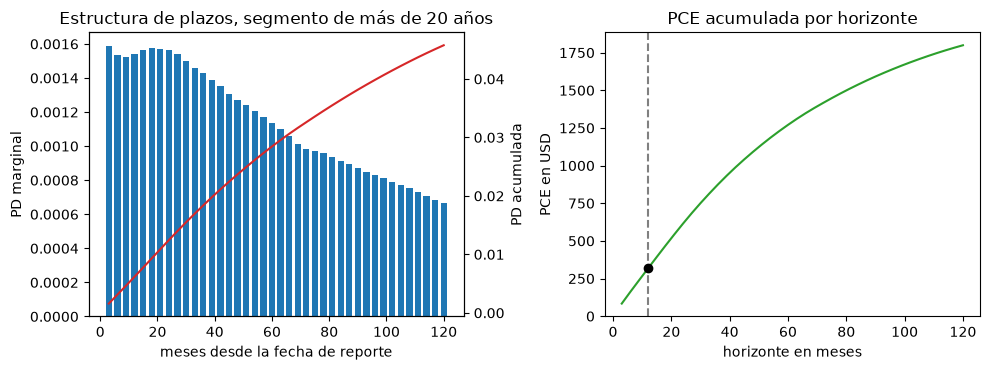

In [11]:
# Dibujar la estructura de plazos del segmento y la PCE acumulada por horizonte
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.bar(months, ts.marginal, width=2.2, color="tab:blue", label="PD marginal")
left.set_xlabel("meses desde la fecha de reporte")
left.set_ylabel("PD marginal")
twin = left.twinx()
twin.plot(months, ts.cumulative, color="tab:red", label="PD acumulada")
twin.set_ylabel("PD acumulada")
left.set_title("Estructura de plazos, segmento de más de 20 años")

running = np.cumsum(contributions)
right.plot(months, running, color="tab:green")
right.axvline(12, color="grey", linestyle="--")
right.scatter([12], [ecl_12], color="black", zorder=3)
right.set_xlabel("horizonte en meses")
right.set_ylabel("PCE en USD")
right.set_title("PCE acumulada por horizonte")
fig.tight_layout()
plt.show()

## Resultados

- **Las identidades cierran.** En los 40 trimestres del segmento de préstamos largos, la supervivencia, la PD marginal y la acumulada cumplen las tres identidades, y el motor reproduce la PD marginal y la acumulada versionadas con tolerancia 1e-9. El artefacto lo calculó el motor 0.5.0 y aquí se lee con el 0.8.1; las funciones de la estructura de plazos dan los mismos arreglos, que es lo que dice la verificación y nada más.
- **Un hazard, tres puertas.** `from_marginal` y `from_cumulative` devuelven el hazard del paso 1. Una PD acumulada que baja se rechaza con un `ValueError` cuyo mensaje nombra la regla, que es cómo un error de entrada se vuelve un mensaje y no una PCE equivocada.
- **El primer año es una parte pequeña de un préstamo largo.** La PD de los primeros 12 meses es 0,0062, la PD de los meses 12 a 120 dado que se sobrevive al mes 12 es 0,0398, y ambas componen la PD de vida completa de 0,0458. Por eso un préstamo que pasa de la Etapa 1 a la Etapa 2 cambia tanto su medición.
- **El prepago importa, y la PD de vida completa de Contraste no lo lleva.** Con un hazard de prepago ilustrativo de 1 % por trimestre, la incidencia acumulada de incumplimiento baja de 0,0458 a 0,0390, y 36 % de los préstamos sale del libro por una de las dos salidas. El C06 trata el prepago como censura (hallazgo `F-PREPAYMENT`), así que en este punto su PCE de vida completa queda del lado cauteloso.
- **La PCE es una suma que se puede leer.** Para la cuenta de la lección (100.000 USD, 8 % anual) la PCE a 12 meses es 317,09 USD (0,32 % de la exposición) y la PCE de vida completa es 1.799,23 USD (1,80 %), 5,67 veces mayor. El motor y la suma escrita a mano coinciden.
- **Convención y tasa no son decisiones equivalentes.** La convención al final del período baja la PCE de vida completa en 0,96 %; una tasa libre de riesgo de 2 % la sube en 24,7 %, por eso IFRS 9 fija la tasa en la TIE.
- **El efecto del horizonte depende del plazo.** La razón entre la PCE de vida completa y la de 12 meses es 2,21 para los préstamos de hasta 5 años, 3,79 de 5 a 10 años, 5,05 de 10 a 20 años y 5,67 sobre 20 años. Los dos segmentos más cortos llevan una pérdida dado el incumplimiento de 1,0, el proxy de severidad del castigo del pipeline, que tiene un sesgo al alza (hallazgo `F-LGD-PROXY`).

Lo que este cuaderno no muestra: la exposición y la tasa son insumos de la lección, no datos del archivo, y el pipeline amortiza el saldo (hallazgo `F-EAD-MODEL`) donde la lección lo mantiene constante. Las etapas, que deciden cuál de las dos PCE lleva un préstamo, son el cuaderno 02; la ponderación de los tres escenarios es el cuaderno 03.

## Resumen

- La supervivencia, la PD marginal y la acumulada son un solo objeto visto de tres maneras; el motor lo construye desde un hazard, una PD marginal o una PD acumulada y rechaza entradas no válidas.
- La PCE de una cuenta es la suma, sobre los períodos, de la PD marginal, la pérdida dado el incumplimiento, la exposición y el factor de descuento. La PCE a 12 meses y la de vida completa son la misma suma cortada en dos horizontes.
- El descuento es a la TIE original, a mitad de período por el ajuste documentado de Contraste; la convención alternativa y, sobre todo, una tasa libre de riesgo cambian la cifra sin cambiar el riesgo.
- Una salida competitiva como el prepago baja la incidencia de incumplimiento y no es el complemento de la supervivencia; el C06 registra su elección (censura) como un hallazgo.
- Un recálculo se compara con el artefacto versionado solo después de nombrar la versión del motor que lo calculó.

**Qué probar a continuación.** Cambia `PREPAY_HAZARD` a 0 y luego a 0,03 y mira la incidencia de incumplimiento; cambia `SEGMENT` a `term-le-60`. Después sigue con el cuaderno 02, que decide cuál de las dos PCE lleva cada préstamo.

## Referencias

- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- Botha, A. y Verster, T. (2025), Approaches for modelling the term-structure of default risk under IFRS 9: a tutorial using discrete-time survival analysis, ecuaciones 6 a 10. https://arxiv.org/abs/2507.15441
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 de junio de 2016, secciones 2.1.1, 2.7.2 y 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf